# 01 — Data Exploration

Explore the cleaned Online Retail II transactions and identify business-level patterns.

Run `python ml/preprocessing.py` first if `transactions.csv` does not exist.


In [1]:
from pathlib import Path
%pip install seaborn
import sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA = ROOT / "data" / "processed" / "transactions.csv"
if not DATA.exists():
    raise FileNotFoundError("Run `python ml/preprocessing.py` first.")

df = pd.read_csv(DATA, parse_dates=["InvoiceDate"])
df.head()


Note: you may need to restart the kernel to use updated packages.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SourceSheet,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,Year 2009-2010,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Year 2009-2010,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Year 2009-2010,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,Year 2009-2010,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,Year 2009-2010,30.0


In [2]:

print("Shape:", df.shape)
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Customers:", df["CustomerID"].nunique())
print("Orders:", df["InvoiceNo"].nunique())
print("Products:", df["StockCode"].nunique())
print("Countries:", df["Country"].nunique())
print("Revenue:", round(df["Revenue"].sum(), 2))


Shape: (793609, 10)
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Customers: 5878
Orders: 36969
Products: 4631
Countries: 41
Revenue: 17685460.64


In [3]:

display(df.info())
display(df.describe(include="all").T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 793609 entries, 0 to 793608
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    793609 non-null  int64         
 1   StockCode    793609 non-null  object        
 2   Description  793609 non-null  object        
 3   Quantity     793609 non-null  int64         
 4   InvoiceDate  793609 non-null  datetime64[ns]
 5   UnitPrice    793609 non-null  float64       
 6   CustomerID   793609 non-null  int64         
 7   Country      793609 non-null  object        
 8   SourceSheet  793609 non-null  object        
 9   Revenue      793609 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(4)
memory usage: 60.5+ MB


None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,793609.0,NaN,NaN,NaN,537423.567202,489434.0,514967.0,537042.0,561616.0,581587.0,26660.238547
StockCode,793609,4631,85123A,5130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,793609,5283,WHITE HANGING HEART T-LIGHT HOLDER,5123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,793609.0,NaN,NaN,NaN,13.4469,1.0,2.0,6.0,12.0,80995.0,144.693151
InvoiceDate,793609,NaN,NaN,NaN,2011-01-02 13:32:54.594164224,2009-12-01 07:45:00,2010-07-07 12:21:00,2010-12-05 10:45:00,2011-07-28 13:02:00,2011-12-09 12:50:00,NaN
UnitPrice,793609.0,NaN,NaN,NaN,3.216821,0.001,1.25,1.95,3.75,10953.5,29.416465
CustomerID,793609.0,NaN,NaN,NaN,15325.072507,12346.0,13975.0,15255.0,16797.0,18287.0,1697.397406
Country,793609,41,United Kingdom,713436,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SourceSheet,793609,2,Year 2009-2010,400916,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,793609.0,NaN,NaN,NaN,22.284854,0.001,4.95,12.48,19.8,168469.6,225.708594


In [4]:

missing = df.isna().sum().sort_values(ascending=False).to_frame("missing_count")
missing["missing_pct"] = missing["missing_count"] / len(df) * 100
display(missing)


,missing_count,missing_pct
InvoiceNo,0,0.0
StockCode,0,0.0
Description,0,0.0
Quantity,0,0.0
InvoiceDate,0,0.0
UnitPrice,0,0.0
CustomerID,0,0.0
Country,0,0.0
SourceSheet,0,0.0
Revenue,0,0.0


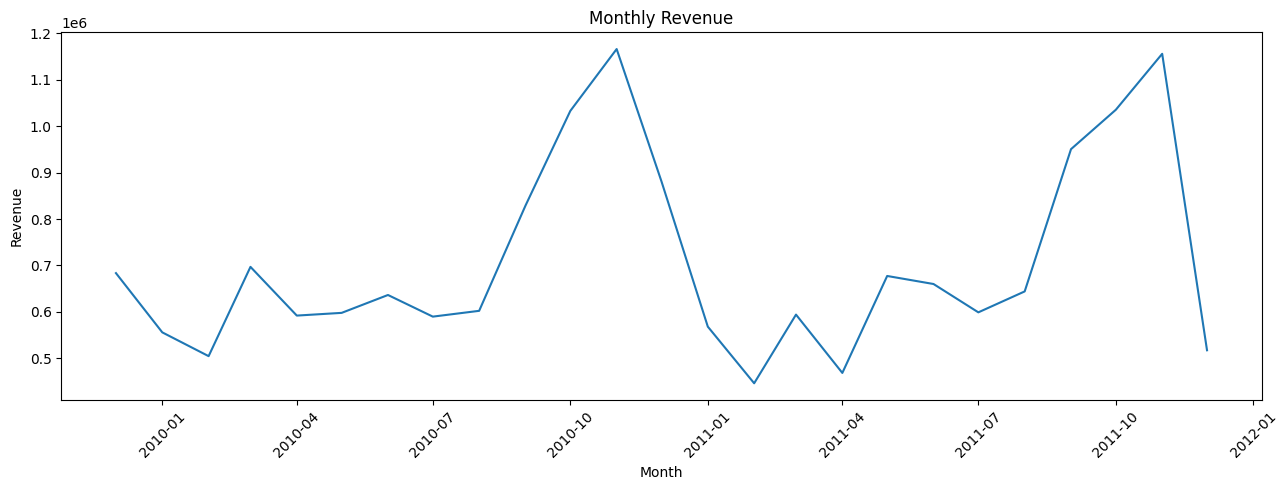

In [6]:
monthly = (
    df.set_index("InvoiceDate")
      .resample("MS")["Revenue"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(13, 5))
sns.lineplot(
    data=monthly,
    x="InvoiceDate",
    y="Revenue"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

       Month  orders
0 2009-12-01    1512
1 2010-01-01    1011
2 2010-02-01    1104
3 2010-03-01    1524
4 2010-04-01    1329


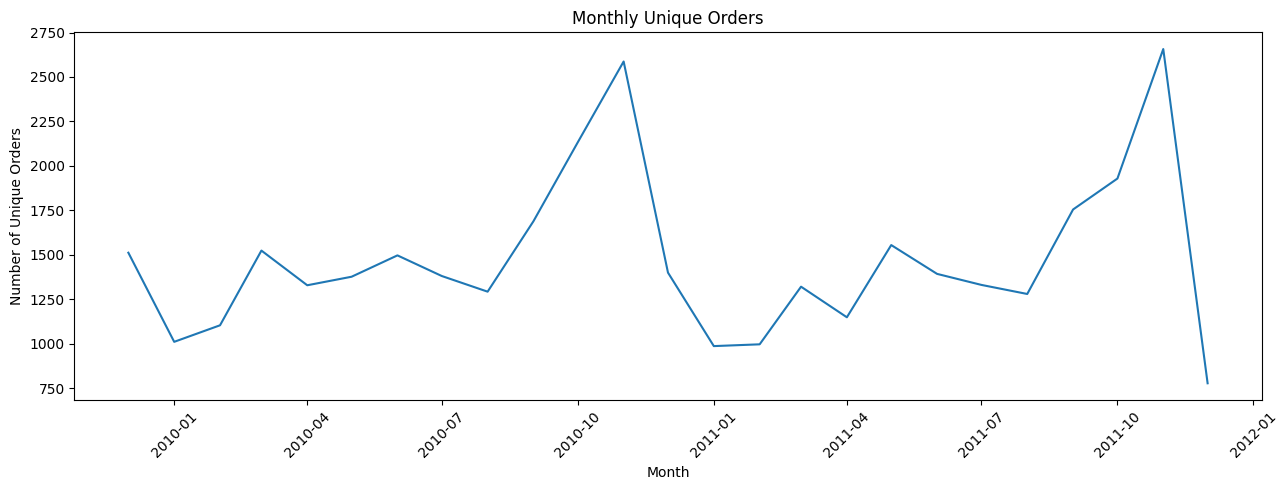

In [9]:
# Make sure InvoiceDate is datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Remove rows with invalid dates
df = df.dropna(subset=["InvoiceDate"])

# Create a month column without using resample()
df["Month"] = (
    df["InvoiceDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Count unique orders per month
monthly_orders = (
    df.groupby("Month")["InvoiceNo"]
      .nunique()
      .reset_index(name="orders")
)

# Display the result
print(monthly_orders.head())

# Plot
plt.figure(figsize=(13, 5))

sns.lineplot(
    data=monthly_orders,
    x="Month",
    y="orders"
)

plt.title("Monthly Unique Orders")
plt.xlabel("Month")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Monthly Orders:


,Month,orders
0,2009-12-01,1512
1,2010-01-01,1011
2,2010-02-01,1104
3,2010-03-01,1524
4,2010-04-01,1329
5,2010-05-01,1377
6,2010-06-01,1497
7,2010-07-01,1381
8,2010-08-01,1293
9,2010-09-01,1689


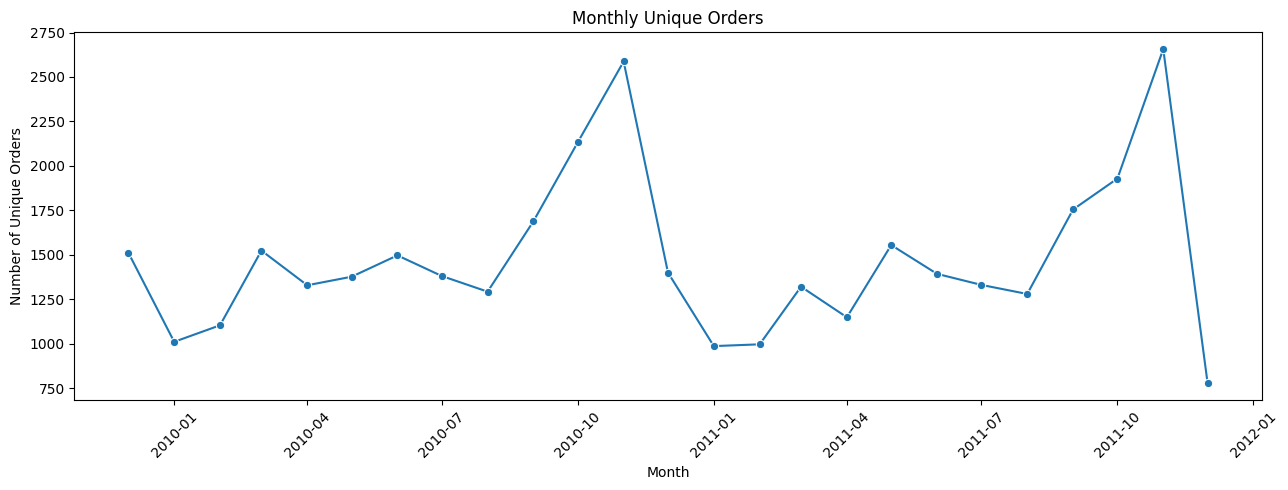

In [11]:
# ============================================
# MONTHLY UNIQUE ORDERS
# ============================================

# Make sure InvoiceDate is datetime
df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"],
    errors="coerce"
)

# Remove invalid dates
df = df.dropna(subset=["InvoiceDate"]).copy()

# Create a month column
# This avoids pandas resample frequency compatibility issues
df["Month"] = (
    df["InvoiceDate"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Calculate unique orders per month
monthly_orders = (
    df.groupby("Month")["InvoiceNo"]
      .nunique()
      .reset_index(name="orders")
)

# Display results
print("Monthly Orders:")
display(monthly_orders.head(12))

# ============================================
# VISUALIZATION
# ============================================

plt.figure(figsize=(13, 5))

sns.lineplot(
    data=monthly_orders,
    x="Month",
    y="orders",
    marker="o"
)

plt.title("Monthly Unique Orders")
plt.xlabel("Month")
plt.ylabel("Number of Unique Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [12]:

country_summary = (
    df.groupby("Country")
      .agg(
          customers=("CustomerID", "nunique"),
          orders=("InvoiceNo", "nunique"),
          revenue=("Revenue", "sum")
      )
      .sort_values("revenue", ascending=False)
)

display(country_summary.head(15))


,customers,orders,revenue
Country,,,
United Kingdom,5350,33541,1.466667e+07
EIRE,5,567,6.213043e+05
Netherlands,22,228,5.542307e+05
Germany,107,789,4.307038e+05
France,95,614,3.550594e+05
Australia,15,95,1.699006e+05
Spain,41,154,1.091272e+05
Switzerland,22,90,1.003653e+05
Sweden,19,104,9.151582e+04


In [13]:

top_products = (
    df.groupby(["StockCode", "Description"])
      .agg(quantity=("Quantity", "sum"), revenue=("Revenue", "sum"))
      .sort_values("revenue", ascending=False)
      .head(20)
)
display(top_products)


,,quantity,revenue
StockCode,Description,,
22423,REGENCY CAKESTAND 3 TIER,24858,285992.35
85123A,WHITE HANGING HEART T-LIGHT HOLDER,93520,251731.26
23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
M,Manual,9501,151951.92
85099B,JUMBO BAG RED RETROSPOT,75597,136684.79
84879,ASSORTED COLOUR BIRD ORNAMENT,79694,126704.06
POST,POSTAGE,5333,126563.04
47566,PARTY BUNTING,23591,103802.53
23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73


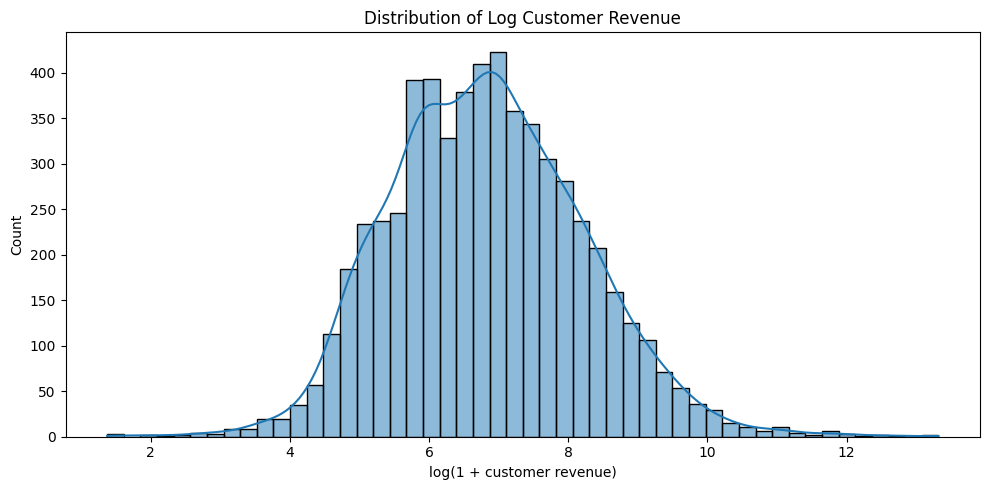

In [14]:

customer_revenue = df.groupby("CustomerID")["Revenue"].sum()

plt.figure(figsize=(10,5))
sns.histplot(np.log1p(customer_revenue), bins=50, kde=True)
plt.title("Distribution of Log Customer Revenue")
plt.xlabel("log(1 + customer revenue)")
plt.tight_layout()
plt.show()


## Business questions

Record the actual results from this notebook in the README:

1. Which country generates the most revenue?
2. Which months are strongest?
3. How concentrated is revenue among top customers?
4. Do order and revenue trends move together?
5. What data-quality issues remain?

Do not hard-code or invent results.
